# 16 · Threshold questions without false flood probabilities

**Time:** 45 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** Calculate fixed-year conditional exceedance, export a documented SQL result, and design a port evidence study.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=16_ar6_uncertainty.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


> **Data identity:** real modeled projections, not observations. AR6 v20210809; workflow `wf_1e`; 20,000 Monte Carlo samples at each decade from 2020 to 2100. Source values are millimetres of relative sea-level change from the 1995–2014 reference period; plots convert them to metres. Background land motion is included.

> **Interpretation:** a workflow distribution is not the assessed IPCC probability box (p-box). The source FAQ says `wf_1e` does not preserve time correlations: do not calculate rates, sample trajectories, or first-crossing dates. The exercise compares distributions at specified years. These data alone cannot map inundation or rank port vulnerability.

![From archive chunks to projection distributions, with flood-risk evidence kept separate](assets/ar6-workflow.svg)

In [2]:
from ar6 import load_ar6, coverage_map, coastline, gauge_summary, summary_sql, export_summary
p, years, gauge_m, grid_m = load_ar6()
print('Samples: scenario, sample, year, unique gauge =', gauge_m.shape)
print('Nearest defined grid samples: sample, year, city =', grid_m.shape)

Samples: scenario, sample, year, unique gauge = (2, 20000, 9, 4)
Nearest defined grid samples: sample, year, city = (20000, 9, 5)


## 1. Define the event precisely

“Relative sea-level change exceeds 0.5 m in 2100 at this projection location, conditional on SSP5-8.5 and `wf_1e`” is answerable here. “Lagos port will flood with probability X” is not. The threshold is relative to the **1995–2014 mean sea-level baseline**, not the elevation of a building, quay, road, or levee.

The fraction of finite samples above a threshold is an empirical estimate within this one workflow. It omits structural uncertainty across workflows and does not assign probabilities to emissions scenarios. Do not label it the overall probability of sea-level rise or of climate harm.

In [3]:
year=2100; threshold_m=.5
t=int(np.where(years==year)[0][0])
for c in p['cities']:
    g=c['gauge_column']
    fractions=[]
    for s in range(2):
        v=gauge_m[s,:,t,g];valid=np.isfinite(v)
        fractions.append(float(np.count_nonzero(v[valid]>threshold_m)/valid.sum()))
    print(c['name'],p['gauges'][g]['name'],dict(zip(p['gauge_scenarios'],fractions)))

Abidjan TAKORADI {'ssp126': 0.52645, 'ssp585': 0.9936}
Lagos TAKORADI {'ssp126': 0.52645, 'ssp585': 0.9936}
Bangkok FORT_PHRACHULA_CHOMKLAO {'ssp126': 1.0, 'ssp585': 1.0}
Ho Chi Minh City VUNGTAU {'ssp126': 0.3678, 'ssp585': 0.9364}
Manila MANILA {'ssp126': 0.9978, 'ssp585': 1.0}


## 2. Inspect threshold sensitivity at grid locations

Use the five nearest defined gridded locations for a second view. The curve is an exceedance fraction at a **fixed year**, not a survival curve through time. A threshold sweep communicates more than one chosen threshold. At large thresholds the empirical tail has fewer samples; apparent numerical precision does not resolve structural model uncertainty.

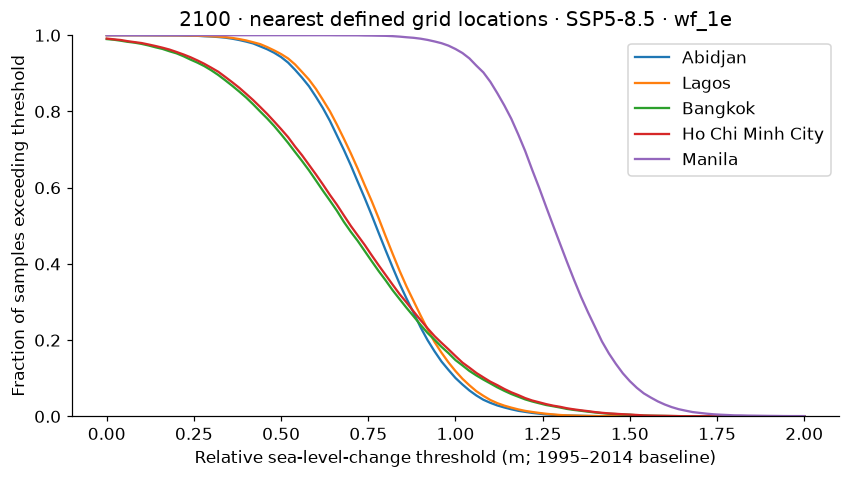

In [4]:
thresholds=np.linspace(0,2,101)
fig,ax=plt.subplots()
for i,c in enumerate(p['cities']):
    v=grid_m[:,t,i]
    fraction=np.array([np.mean(v>h) for h in thresholds])
    assert np.all(np.diff(fraction)<=0)
    ax.plot(thresholds,fraction,label=c['name'])
ax.set(xlabel='Relative sea-level-change threshold (m; 1995–2014 baseline)',ylabel='Fraction of samples exceeding threshold',ylim=(0,1),title=f'{year} · nearest defined grid locations · SSP5-8.5 · wf_1e')
ax.legend();plt.show()

## 3. Export a small, auditable selection

Summarise unique gauge locations before joining city labels. The query selects 2100 SSP5-8.5 records whose **median**, not every sample, exceeds 0.5 m. Every output point retains quantiles, units, baseline, workflow, scenario, data version, sample count and a link to exact provenance.

In [5]:
summary=gauge_summary(p,years,gauge_m)
con=summary_sql(summary)
ids={r[0] for r in con.execute("SELECT gauge_id FROM projections WHERE year=2100 AND scenario='ssp585' AND p50_m>0.5")}
selected=[r for r in summary if r['gauge_id'] in ids and r['year']==2100 and r['scenario']=='ssp585']
print('Unique gauges exported:',export_summary(selected))
con.close()
print('Download ar6-projections.geojson from the file browser; retain its attribution.')

Unique gauges exported: 4
Download ar6-projections.geojson from the file browser; retain its attribution.


## 4. Avoid a tempting but invalid calculation

Do **not** subtract consecutive `wf_1e` samples to estimate rates, identify each sample's first threshold crossing, or use the same sample number as a paired counterfactual across scenarios. This workflow's time correlations are not valid for those tasks. Use the authors' appropriately constructed rate or milestone products, following their documentation. Connecting medians in a plot is a display device; it does not fix that limitation.

## 5. Design a five-city evidence clinic

Divide into teams for Abidjan, Lagos, Bangkok, Ho Chi Minh City and Manila. Each team should document:

| Evidence needed | Why it matters | A test before using it |
|---|---|---|
| Port/transport asset geometry and critical services | Establishes exposure, not assumed from a city point | Verify coordinates, date, ownership and reuse terms |
| Local elevation/bathymetry and vertical datum | Links land and water heights | Reconcile datum, resolution, error and survey epoch |
| Tide, storm-surge, wave and river levels | Describes coastal and compound flood drivers | Check time support, joint events and hydraulic connectivity |
| InSAR/GNSS and local subsidence interpretation | Evaluates changing ground levels | Resolve overlap with AR6 background land motion before combining |
| Defenses, drainage and maintenance | Changes the pathway from hazard to impact | Validate crest levels, operations and plausible failure assumptions |
| Population, livelihoods and community knowledge | Supports an equitable vulnerability assessment | Protect privacy; validate representativeness and local relevance |

Use [NASA's IPCC tool](https://sealevel.nasa.gov/ipcc-ar6-sea-level-projection-tool) to inspect assessed products. Use STAC/browser GIS to discover additional Earth observation evidence. Check each source's license; no proprietary port or asset data is bundled here.

**Submission:** one reproducible figure, one source table, the selected GeoJSON, and a short statement separating the modeled hazard from exposure, vulnerability and potential impacts. Cite the three required AR6 works listed below.

## Try it yourself

Repeat the fixed-year threshold question for 2050 and 2100, then write a sentence that avoids implying a first-crossing time or flood probability.

## Check your reasoning

Report each year’s conditional sample fraction separately, with scenario, workflow, location and baseline. A change between these two fractions does not identify individual trajectories or a time-to-flood distribution.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [Fox-Kemper et al. (2021), IPCC AR6 WG1 Chapter 9: Ocean, Cryosphere and Sea Level Change](https://doi.org/10.1017/9781009157896.011).
- [Kopp et al. (2023), FACTS v1.0, Geoscientific Model Development 16, 7461–7489](https://doi.org/10.5194/gmd-16-7461-2023).
- [Garner et al. (2021), IPCC AR6 Sea Level Projections, version 20210809](https://doi.org/10.5281/zenodo.5914709), accessed 2026-10-13. Modified extracts under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
- [Rutgers-ESSP source guide and workflow FAQ](https://github.com/Rutgers-ESSP/IPCC-AR6-Sea-Level-Projections/tree/8ee75128d8f6d9a8ba9825f47c92d11955d0651e).
- [Exact source objects, checksums, transformations and location distances](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/ar6-provenance.json).
- We thank the projection authors for developing and making the sea-level rise projections available, multiple funding agencies for supporting the development of the projections, and the NASA Sea Level Change Team for developing and hosting the IPCC AR6 Sea Level Projection Tool.

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [6]:
print('LESSON COMPLETE: 16_ar6_uncertainty')

LESSON COMPLETE: 16_ar6_uncertainty
